# GoEmotions Project 2 — pretrained embeddings and compositional encoders

**Goal.** Extend the Project 1 multilabel GoEmotions classifier with Tutorial 2 concepts and answer all six project sections.

| Project section | Operational question |
|---|---|
| 1. Embedding choice | Does English GloVe align with our tokenizer and cover Reddit comments? |
| 2. Embedding structure | Do emotion words occupy meaningful—and imperfect—semantic neighbourhoods? |
| 3. Embed-and-pool | Do mean/sum pooling and frozen/fine-tuned vectors change performance? |
| 4. Recurrent encoder | Does a bidirectional GRU improve on order-invariant pooling, and does pretraining help? |
| 5. Uncertainty | Are conclusions stable over three matched random seeds? |
| 6. Error analysis | Which text properties predict errors and differences between pooling and recurrence? |

The official train/dev/test split is respected. The development set controls early stopping, model selection and one global multilabel threshold. The test set is inspected once, after all choices are fixed.


## Cell 1 — setup, data and reproducible configuration

This cell imports the compact helper module, finds the same GoEmotions files used in Project 1, fixes all experiment settings, and prints the environment/data configuration before any modelling decision.


In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "part2" / "goemotions_project2.py").is_file():
        ROOT = candidate; break
else:
    raise FileNotFoundError("Run from the Assignment 2 repository or its part2 directory")
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from part2.goemotions_project2 import *

SEEDS = [0, 3, 5]
SCREEN_SEED = 0
SCREEN_ROWS = 12_000
SCREEN_EPOCHS = 6
CONFIRM_EPOCHS = 8
PATIENCE = 2
BATCH_SIZE = 256
MAX_LENGTH = 80
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATA_DIR = locate_data(ROOT)
RESULTS_DIR = ROOT / "part2" / "p2r"
CACHE_DIR = ROOT / "part2" / ".cache"
PLOTS_DIR = RESULTS_DIR / "plots"
for folder in (RESULTS_DIR, CACHE_DIR, PLOTS_DIR): folder.mkdir(parents=True, exist_ok=True)
SPLITS, TARGETS, LABELS = load_goemotions(DATA_DIR)

settings = pd.DataFrame({
    "setting": ["device", "train/dev/test", "labels", "screen rows/epochs", "confirmation seeds/epochs", "maximum tokens"],
    "value": [DEVICE, "/".join(f"{len(SPLITS[s]):,}" for s in ("train","dev","test")), len(LABELS),
              f"{SCREEN_ROWS:,}/{SCREEN_EPOCHS}", f"{SEEDS}/{CONFIRM_EPOCHS}", MAX_LENGTH]
})
display(settings)


,setting,value
0,device,cpu
1,train/dev/test,"43,410/5,426/5,427"
2,labels,28
3,screen rows/epochs,"12,000/6"
4,confirmation seeds/epochs,"[0, 3, 5]/8"
5,maximum tokens,80


## Cells 2–3 — embedding suitability and structure

We use the standard 50-dimensional **GloVe Wikipedia 2014 + Gigaword 5 (6B-token)** vectors distributed through the Gensim data mirror. English matches GoEmotions, 50 dimensions keep the repeated CPU experiment feasible, and the tutorial's loader/tokenisation assumptions are directly reusable. The newer 2024 tutorial archive was attempted first but its Stanford endpoint was unreachable from this machine; this established release is the documented fallback. Pooling removes punctuation and common stopwords; the GRU retains the full sequence. Coverage is measured rather than assumed. The heatmap then tests whether a selection of emotion names has coherent cosine structure; it is descriptive evidence, not proof that isolated word vectors fully represent emotions in context.


,split,tokens,types,token_coverage,type_coverage,oov_tokens
0,train,683061,26697,96.9%,84.7%,21398
1,dev,85161,8868,96.9%,91.7%,2681
2,test,84826,8763,96.7%,91.5%,2761


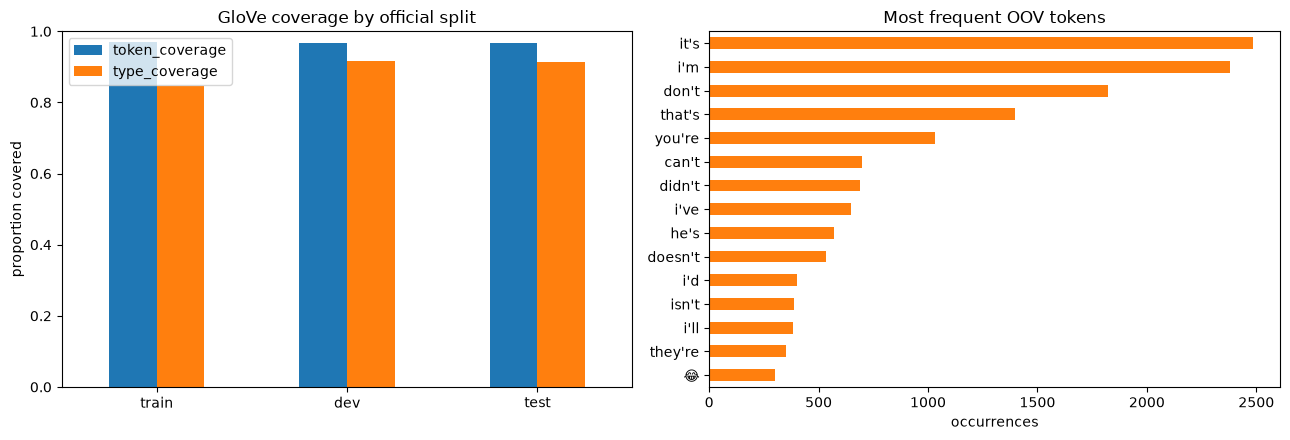

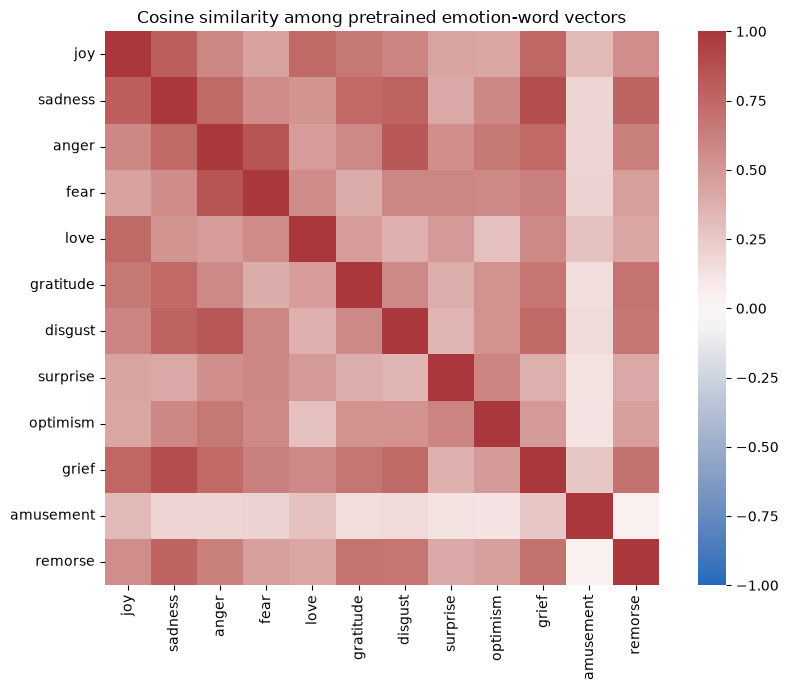

,emotion,nearest emotion,cosine
0,joy,sadness,0.804
1,sadness,grief,0.884
2,anger,fear,0.845
3,fear,anger,0.845
4,love,joy,0.736
5,gratitude,sadness,0.744
6,disgust,anger,0.840
7,surprise,optimism,0.606
8,optimism,anger,0.670
9,grief,sadness,0.884


In [2]:
# Tokenise first so the large archive can be streamed into a small task-specific embedding table.
sequence_tokens = {split: [tokenize(text) for text in frame.text] for split, frame in SPLITS.items()}
pool_tokens = {split: [tokenize_for_pool(text) for text in frame.text] for split, frame in SPLITS.items()}
probe_emotions = ["joy", "sadness", "anger", "fear", "love", "gratitude", "disgust", "surprise",
                  "optimism", "grief", "amusement", "remorse"]
required_tokens = set(probe_emotions)
for split in sequence_tokens:
    required_tokens.update(token for document in sequence_tokens[split] for token in document)

glove_archive = download_glove(CACHE_DIR / "glove-wiki-gigaword-50.gz")
EMBEDDINGS = load_glove_subset(glove_archive, required_tokens, CACHE_DIR / "goemotions_glove50_subset.npz")

sequence_ids, pool_ids = {}, {}
for split in SPLITS:
    sequence_ids[split], sequence_tokens[split] = encode_token_lists(sequence_tokens[split], EMBEDDINGS, MAX_LENGTH)
    pool_ids[split], pool_tokens[split] = encode_token_lists(pool_tokens[split], EMBEDDINGS, MAX_LENGTH)

coverage = coverage_frame(sequence_tokens, EMBEDDINGS)
coverage.to_csv(RESULTS_DIR / "embedding_coverage.csv", index=False)
display(coverage.assign(token_coverage=lambda d: d.token_coverage.map("{:.1%}".format),
                        type_coverage=lambda d: d.type_coverage.map("{:.1%}".format)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
coverage.set_index("split")[["token_coverage", "type_coverage"]].plot.bar(ax=axes[0], ylim=(0,1), rot=0)
axes[0].set(title="GloVe coverage by official split", ylabel="proportion covered", xlabel="")
known = set(EMBEDDINGS.word_to_id) - {"<pad>", "<unk>"}
oov = pd.Series([token for docs in sequence_tokens.values() for doc in docs for token in doc if token not in known]).value_counts().head(15)
oov.sort_values().plot.barh(ax=axes[1], color="tab:orange")
axes[1].set(title="Most frequent OOV tokens", xlabel="occurrences", ylabel="")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "embedding_coverage_and_oov.png", dpi=180, bbox_inches="tight"); plt.show()

emotion_vectors = np.stack([EMBEDDINGS.vectors[EMBEDDINGS.word_to_id[word]] for word in probe_emotions])
normalised = emotion_vectors / np.maximum(np.linalg.norm(emotion_vectors, axis=1, keepdims=True), 1e-12)
emotion_similarity = pd.DataFrame(normalised @ normalised.T, index=probe_emotions, columns=probe_emotions)
plt.figure(figsize=(9, 7)); sns.heatmap(emotion_similarity, cmap="vlag", center=0, vmin=-1, vmax=1, square=True)
plt.title("Cosine similarity among pretrained emotion-word vectors"); plt.tight_layout()
plt.savefig(PLOTS_DIR / "emotion_word_similarity.png", dpi=180, bbox_inches="tight"); plt.show()

nearest = []
for emotion in probe_emotions:
    row = emotion_similarity.loc[emotion].drop(emotion).sort_values(ascending=False)
    nearest.append({"emotion": emotion, "nearest emotion": row.index[0], "cosine": row.iloc[0]})
display(pd.DataFrame(nearest).round(3))


## Cells 4–5 — staged architecture search

The cheap screen changes one meaningful design property at a time on the same 12,000 training comments: mean versus sum pooling; frozen versus fine-tuned pretrained embeddings; pooling versus a bidirectional GRU; and pretrained versus random GRU embeddings. All systems use weighted binary cross-entropy because each comment may have multiple, strongly imbalanced emotion labels. Macro-F1 chooses one pooling and one recurrent finalist; this is a screening result, not the final estimate.


GloVe mean, frozen       macro-F1=0.113  threshold=0.35


GloVe sum, frozen        macro-F1=0.118  threshold=0.35


GloVe mean, tuned        macro-F1=0.134  threshold=0.40


GloVe BiGRU, frozen      macro-F1=0.145  threshold=0.35


GloVe BiGRU, tuned       macro-F1=0.171  threshold=0.40


Random BiGRU, tuned      macro-F1=0.141  threshold=0.50


,system,encoder,threshold,best_epoch,minutes,macro_f1,micro_f1,macro_precision,micro_precision,macro_recall,micro_recall,hamming_loss
0,"GloVe BiGRU, tuned",gru,0.40,6,0.6066,0.1708,0.3093,0.1503,0.2028,0.3586,0.6508,0.1221
1,"GloVe BiGRU, frozen",gru,0.35,6,0.5212,0.1447,0.2620,0.1130,0.1623,0.3764,0.6788,0.1606
2,"Random BiGRU, tuned",gru,0.50,6,0.6079,0.1412,0.2912,0.1160,0.2250,0.2293,0.4129,0.0844
3,"GloVe mean, tuned",pool,0.40,6,0.1100,0.1339,0.2936,0.1067,0.1987,0.2679,0.5625,0.1137
4,"GloVe sum, frozen",pool,0.35,6,0.0865,0.1181,0.2486,0.0792,0.1535,0.3414,0.6530,0.1657
5,"GloVe mean, frozen",pool,0.35,6,0.0856,0.1131,0.2420,0.0781,0.1491,0.3200,0.6423,0.1690


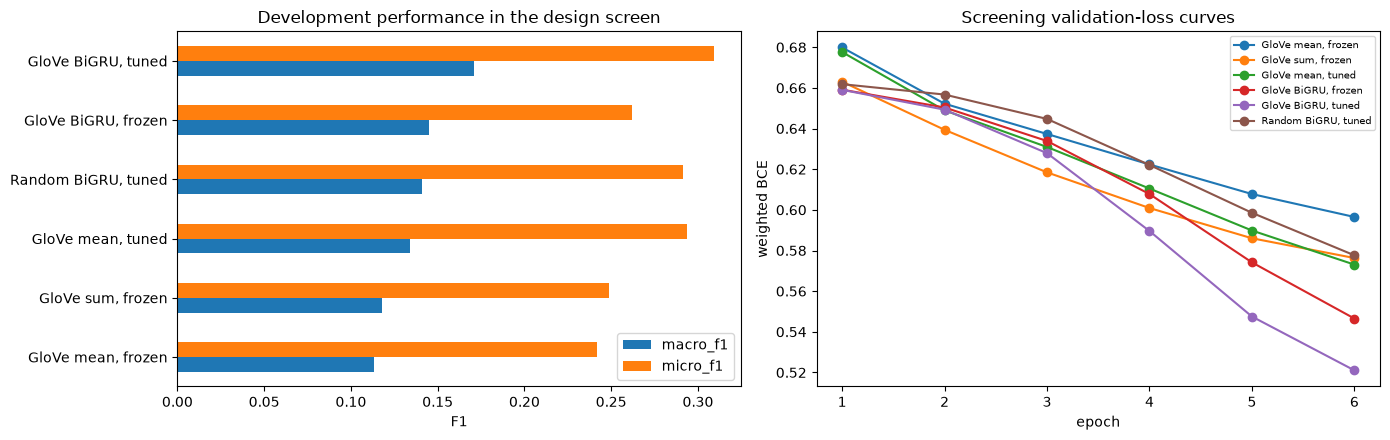

In [3]:
screen_configs = {
    "GloVe mean, frozen": dict(encoder="pool", pooling="mean", freeze_embeddings=True, learning_rate=1e-3),
    "GloVe sum, frozen": dict(encoder="pool", pooling="sum", freeze_embeddings=True, learning_rate=1e-3),
    "GloVe mean, tuned": dict(encoder="pool", pooling="mean", freeze_embeddings=False, learning_rate=1e-3),
    "GloVe BiGRU, frozen": dict(encoder="gru", freeze_embeddings=True, bidirectional=True, learning_rate=1e-3),
    "GloVe BiGRU, tuned": dict(encoder="gru", freeze_embeddings=False, bidirectional=True, learning_rate=1e-3),
    "Random BiGRU, tuned": dict(encoder="gru", freeze_embeddings=False, random_embeddings=True, bidirectional=True, learning_rate=1e-3),
}

rng = np.random.default_rng(SCREEN_SEED)
screen_index = np.sort(rng.choice(len(SPLITS["train"]), min(SCREEN_ROWS, len(SPLITS["train"])), replace=False))
screen_runs, screen_rows = {}, []
for name, config in screen_configs.items():
    source = pool_ids if config["encoder"] == "pool" else sequence_ids
    result = train_model(
        config, [source["train"][i] for i in screen_index], TARGETS["train"][screen_index],
        source["dev"], TARGETS["dev"], EMBEDDINGS.vectors, EMBEDDINGS.pad_id,
        SCREEN_SEED, epochs=SCREEN_EPOCHS, patience=PATIENCE, batch_size=BATCH_SIZE, device=DEVICE)
    screen_runs[name] = result
    screen_rows.append({"system": name, "encoder": config["encoder"], "threshold": result["threshold"],
                        "best_epoch": result["best_epoch"], "minutes": result["elapsed_seconds"] / 60, **result["metrics"]})
    print(f"{name:24s} macro-F1={result['metrics']['macro_f1']:.3f}  threshold={result['threshold']:.2f}")

screen = pd.DataFrame(screen_rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
screen.to_csv(RESULTS_DIR / "screening_results.csv", index=False)
display(screen.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
screen.sort_values("macro_f1").plot.barh(x="system", y=["macro_f1", "micro_f1"], ax=axes[0])
axes[0].set(title="Development performance in the design screen", xlabel="F1", ylabel="")
for name, result in screen_runs.items():
    h = result["history"]
    axes[1].plot(h.epoch, h.validation_loss, marker="o", label=name)
axes[1].set(title="Screening validation-loss curves", xlabel="epoch", ylabel="weighted BCE")
axes[1].legend(fontsize=7); plt.tight_layout()
plt.savefig(PLOTS_DIR / "design_screen.png", dpi=180, bbox_inches="tight"); plt.show()


## Cell 6 — repeat the consequential comparison

The best pooling and best recurrent designs from the screen are retrained on **all** official training comments with three matched seeds. Points expose optimisation variance; mean ± one standard deviation summarises it. Architecture selection still uses only development Macro-F1.


GloVe mean, tuned        seed=0 macro-F1=0.276


GloVe mean, tuned        seed=3 macro-F1=0.281


GloVe mean, tuned        seed=5 macro-F1=0.279


GloVe BiGRU, tuned       seed=0 macro-F1=0.363


GloVe BiGRU, tuned       seed=3 macro-F1=0.370


GloVe BiGRU, tuned       seed=5 macro-F1=0.362


,system,seed,threshold,best_epoch,minutes,macro_f1,micro_f1,macro_precision,micro_precision,macro_recall,micro_recall,hamming_loss
0,"GloVe mean, tuned",0,0.55,8,0.3348,0.2762,0.4175,0.2482,0.3571,0.3333,0.5024,0.0589
1,"GloVe mean, tuned",3,0.50,8,0.3464,0.2811,0.4084,0.2661,0.3196,0.3769,0.5655,0.0688
2,"GloVe mean, tuned",5,0.55,8,0.3871,0.2792,0.4112,0.2931,0.3539,0.3364,0.4906,0.0590
3,"GloVe BiGRU, tuned",0,0.65,8,3.4354,0.3633,0.4861,0.3278,0.4267,0.4383,0.5647,0.0501
4,"GloVe BiGRU, tuned",3,0.65,8,2.3705,0.3702,0.4911,0.3613,0.4319,0.4433,0.5693,0.0495
5,"GloVe BiGRU, tuned",5,0.65,7,2.4188,0.3618,0.4766,0.3354,0.4309,0.4367,0.5332,0.0492


,macro_f1_mean,macro_f1_sd,micro_f1_mean,micro_f1_sd,threshold_mean,minutes_mean
system,,,,,,
"GloVe BiGRU, tuned",0.3651,0.0045,0.4846,0.0074,0.6500,2.7416
"GloVe mean, tuned",0.2789,0.0025,0.4123,0.0047,0.5333,0.3561


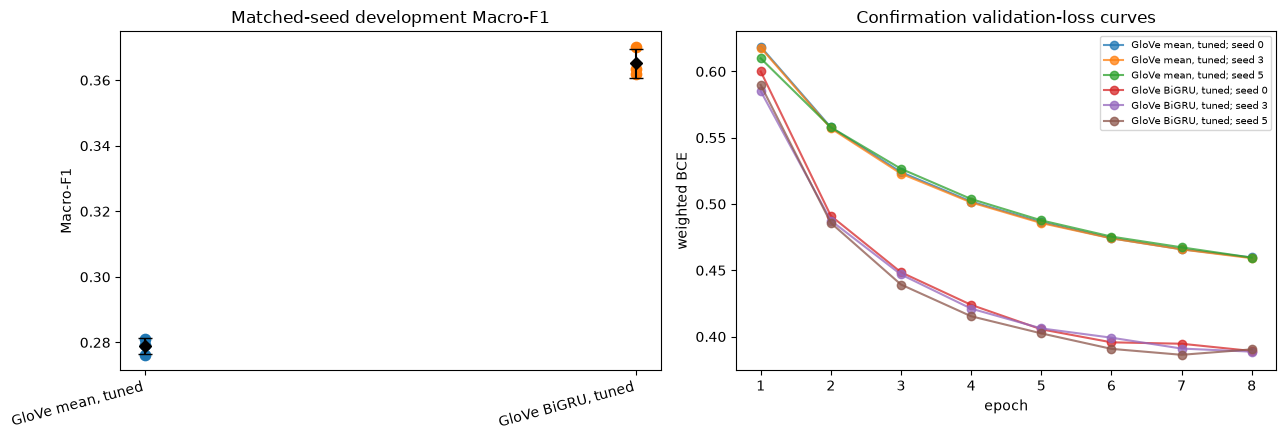

In [4]:
best_pool = screen.loc[screen.encoder.eq("pool")].sort_values("macro_f1", ascending=False).iloc[0].system
best_recurrent = screen.loc[screen.encoder.eq("gru")].sort_values("macro_f1", ascending=False).iloc[0].system
finalists = [best_pool, best_recurrent]
confirm_runs, confirm_rows = {}, []

for name in finalists:
    config = screen_configs[name]
    source = pool_ids if config["encoder"] == "pool" else sequence_ids
    confirm_runs[name] = []
    for seed in SEEDS:
        result = train_model(
            config, source["train"], TARGETS["train"], source["dev"], TARGETS["dev"],
            EMBEDDINGS.vectors, EMBEDDINGS.pad_id, seed, epochs=CONFIRM_EPOCHS,
            patience=PATIENCE, batch_size=BATCH_SIZE, device=DEVICE)
        confirm_runs[name].append(result)
        confirm_rows.append({"system": name, "seed": seed, "threshold": result["threshold"],
                             "best_epoch": result["best_epoch"], "minutes": result["elapsed_seconds"] / 60,
                             **result["metrics"]})
        print(f"{name:24s} seed={seed} macro-F1={result['metrics']['macro_f1']:.3f}")

confirmation = pd.DataFrame(confirm_rows)
confirmation.to_csv(RESULTS_DIR / "confirmation_results.csv", index=False)
summary = confirmation.groupby("system").agg(
    macro_f1_mean=("macro_f1","mean"), macro_f1_sd=("macro_f1","std"),
    micro_f1_mean=("micro_f1","mean"), micro_f1_sd=("micro_f1","std"),
    threshold_mean=("threshold","mean"), minutes_mean=("minutes","mean")).sort_values("macro_f1_mean", ascending=False)
display(confirmation.round(4)); display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for i, name in enumerate(finalists):
    values = confirmation.loc[confirmation.system.eq(name), "macro_f1"]
    axes[0].scatter(np.full(len(values), i), values, s=55, label=name)
    axes[0].errorbar(i, values.mean(), yerr=values.std(), fmt="D", color="black", capsize=5)
axes[0].set_xticks(range(len(finalists)), finalists, rotation=15, ha="right")
axes[0].set(title="Matched-seed development Macro-F1", ylabel="Macro-F1")
for name in finalists:
    for seed, result in zip(SEEDS, confirm_runs[name]):
        h = result["history"]
        axes[1].plot(h.epoch, h.validation_loss, marker="o", alpha=.75, label=f"{name}; seed {seed}")
axes[1].set(title="Confirmation validation-loss curves", xlabel="epoch", ylabel="weighted BCE")
axes[1].legend(fontsize=7); plt.tight_layout()
plt.savefig(PLOTS_DIR / "confirmation.png", dpi=180, bbox_inches="tight"); plt.show()


## Cell 7 — final choice, threshold and untouched test evaluation

The architecture with the highest mean development Macro-F1 is fixed. Its three seed models are ensembled by averaging probabilities. One global threshold is selected on the ensemble's development predictions and then reused unchanged on test. The Project 1 BPE-indicator log-linear test result is included as a historical reference, not re-tuned here.


,system,evaluation,threshold,macro_f1,micro_f1,hamming_loss,macro_precision,micro_precision,macro_recall,micro_recall
0,Project 1: BPE indicator + log-linear,held-out test,0.15,0.3608,0.4805,0.0569,NaN,NaN,NaN,NaN
1,"Project 2: GloVe BiGRU, tuned ensemble",held-out test,0.65,0.3674,0.4938,0.0467,0.3475,0.4501,0.4298,0.5468


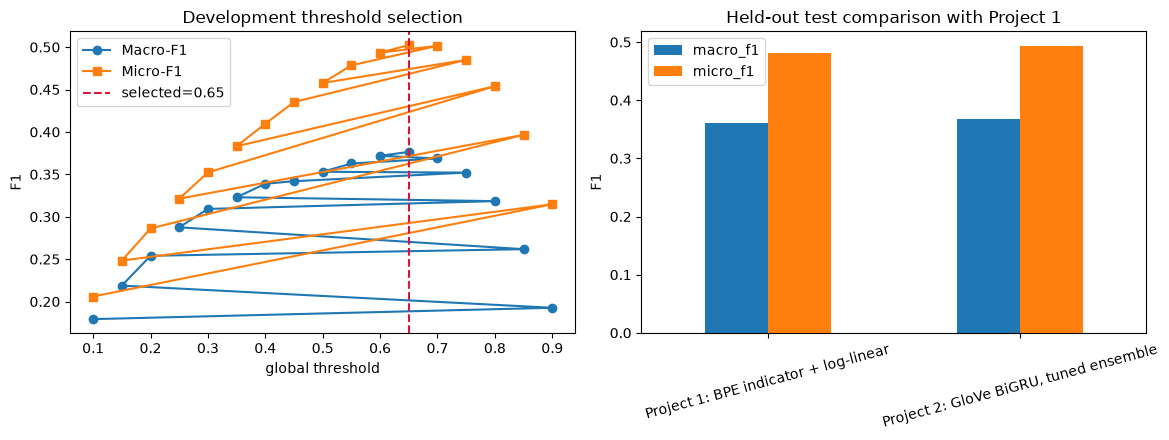

Selected: GloVe BiGRU, tuned; threshold=0.65


In [5]:
SELECTED = summary.index[0]
selected_config = screen_configs[SELECTED]
selected_source = pool_ids if selected_config["encoder"] == "pool" else sequence_ids
dev_ensemble = np.mean([run["probabilities"] for run in confirm_runs[SELECTED]], axis=0)
FINAL_THRESHOLD, threshold_curve = select_threshold(TARGETS["dev"], dev_ensemble)

test_loader = probability_loader(selected_source["test"], TARGETS["test"], EMBEDDINGS.pad_id, BATCH_SIZE)
test_members = [predict_probabilities(run["model"], test_loader, DEVICE) for run in confirm_runs[SELECTED]]
test_probabilities = np.mean(test_members, axis=0)
test_metrics = multilabel_metrics(TARGETS["test"], test_probabilities, FINAL_THRESHOLD)
final_table = pd.DataFrame([
    {"system": "Project 1: BPE indicator + log-linear", "evaluation": "held-out test", "threshold": .15,
     "macro_f1": .360756, "micro_f1": .480485, "hamming_loss": .056938},
    {"system": f"Project 2: {SELECTED} ensemble", "evaluation": "held-out test", "threshold": FINAL_THRESHOLD, **test_metrics},
])
display(final_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(threshold_curve.threshold, threshold_curve.macro_f1, marker="o", label="Macro-F1")
axes[0].plot(threshold_curve.threshold, threshold_curve.micro_f1, marker="s", label="Micro-F1")
axes[0].axvline(FINAL_THRESHOLD, color="crimson", linestyle="--", label=f"selected={FINAL_THRESHOLD:.2f}")
axes[0].set(title="Development threshold selection", xlabel="global threshold", ylabel="F1"); axes[0].legend()
final_table.set_index("system")[["macro_f1","micro_f1"]].plot.bar(ax=axes[1], rot=15)
axes[1].set(title="Held-out test comparison with Project 1", ylabel="F1", xlabel="")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "final_threshold_and_test.png", dpi=180, bbox_inches="tight"); plt.show()

with open(RESULTS_DIR / "run_config.json", "w", encoding="utf-8") as handle:
    json.dump({"seeds": SEEDS, "screen_rows": SCREEN_ROWS, "screen_epochs": SCREEN_EPOCHS,
               "confirmation_epochs": CONFIRM_EPOCHS, "selected_system": SELECTED,
               "selected_threshold": FINAL_THRESHOLD, "device": DEVICE}, handle, indent=2)
pd.DataFrame([test_metrics]).assign(system=SELECTED, threshold=FINAL_THRESHOLD).to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
print(f"Selected: {SELECTED}; threshold={FINAL_THRESHOLD:.2f}")


## Cell 8 — per-emotion performance

Aggregate F1 can hide severe label-level failures. This cell plots held-out test F1 for every emotion, marks overall Macro-F1, and relates F1 to label support. The accompanying table makes the strongest and weakest emotions directly reportable.


,emotion,support,predicted,precision,recall,f1
21,pride,16,0,0.000,0.000,0.000
23,relief,11,0,0.000,0.000,0.000
19,nervousness,23,0,0.000,0.000,0.000
16,grief,6,0,0.000,0.000,0.000
12,embarrassment,37,4,0.250,0.027,0.049
22,realization,145,25,0.400,0.069,0.118
27,neutral,1787,1491,0.630,0.525,0.573
0,admiration,504,759,0.498,0.750,0.599
24,remorse,56,88,0.500,0.786,0.611
1,amusement,264,320,0.678,0.822,0.743


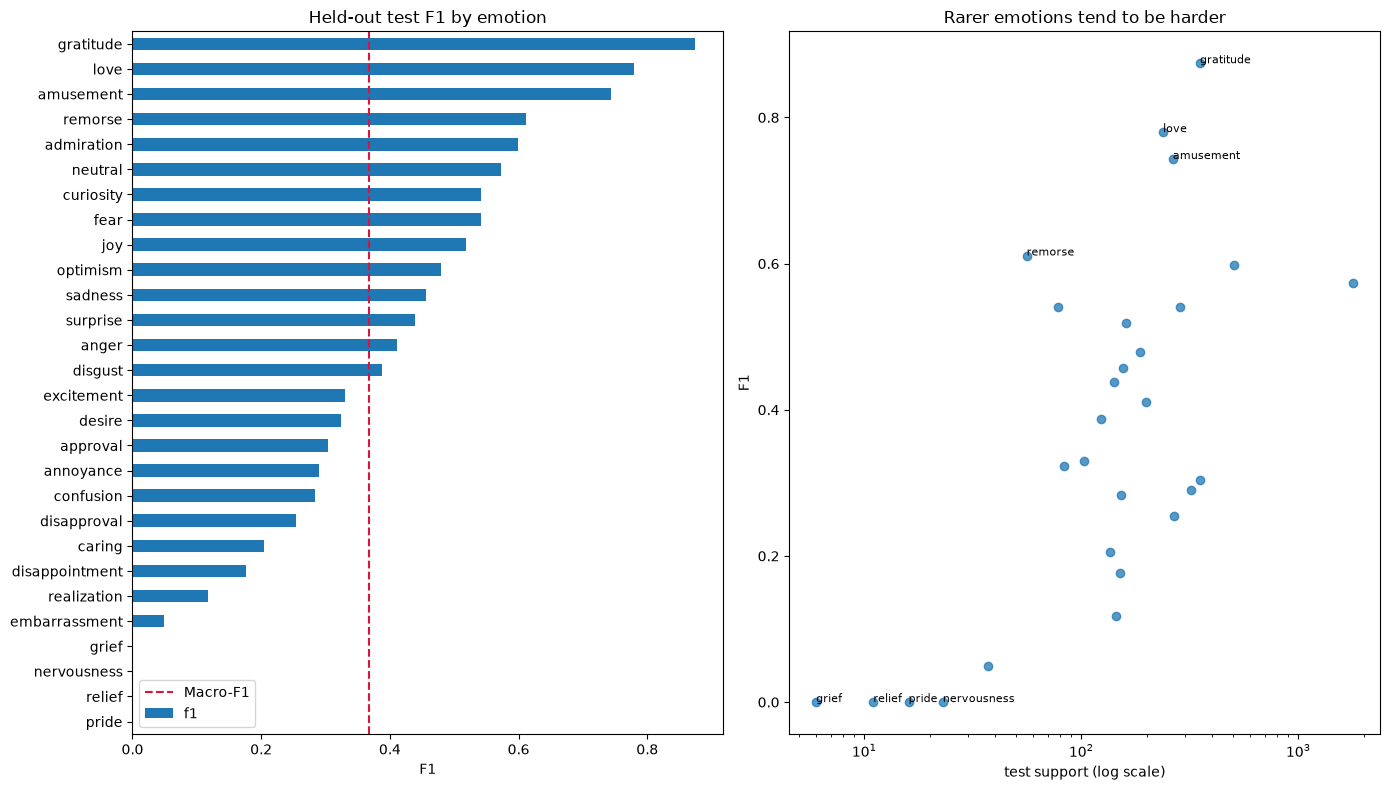

In [6]:
test_predictions = (test_probabilities >= FINAL_THRESHOLD).astype(int)
precision, recall, f1, support = precision_recall_fscore_support(
    TARGETS["test"], test_predictions, average=None, zero_division=0)
per_emotion = pd.DataFrame({"emotion": LABELS, "support": support, "predicted": test_predictions.sum(0),
                            "precision": precision, "recall": recall, "f1": f1}).sort_values("f1")
per_emotion.to_csv(RESULTS_DIR / "per_emotion_test.csv", index=False)
display(pd.concat([per_emotion.head(6), per_emotion.tail(6)]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
per_emotion.plot.barh(x="emotion", y="f1", legend=False, ax=axes[0], color="tab:blue")
axes[0].axvline(test_metrics["macro_f1"], color="crimson", linestyle="--", label="Macro-F1")
axes[0].set(title="Held-out test F1 by emotion", xlabel="F1", ylabel=""); axes[0].legend()
axes[1].scatter(per_emotion.support, per_emotion.f1, alpha=.75)
for _, row in pd.concat([per_emotion.head(4), per_emotion.tail(4)]).iterrows():
    axes[1].annotate(row.emotion, (row.support, row.f1), fontsize=8)
axes[1].set_xscale("log"); axes[1].set(title="Rarer emotions tend to be harder", xlabel="test support (log scale)", ylabel="F1")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "per_emotion_test_analysis.png", dpi=180, bbox_inches="tight"); plt.show()


## Cell 9 — Tutorial-2-style error analysis

We analyse the development set because test remains a final estimate. For each finalist, the response is per-comment multilabel F1. Grouped plots test whether sequence length, OOV rate, negation and label cardinality distinguish pooling from recurrence. A sparse logistic model then predicts whether the selected system gets the **entire** label set exactly right; coefficient signs describe conditional associations, not causes.


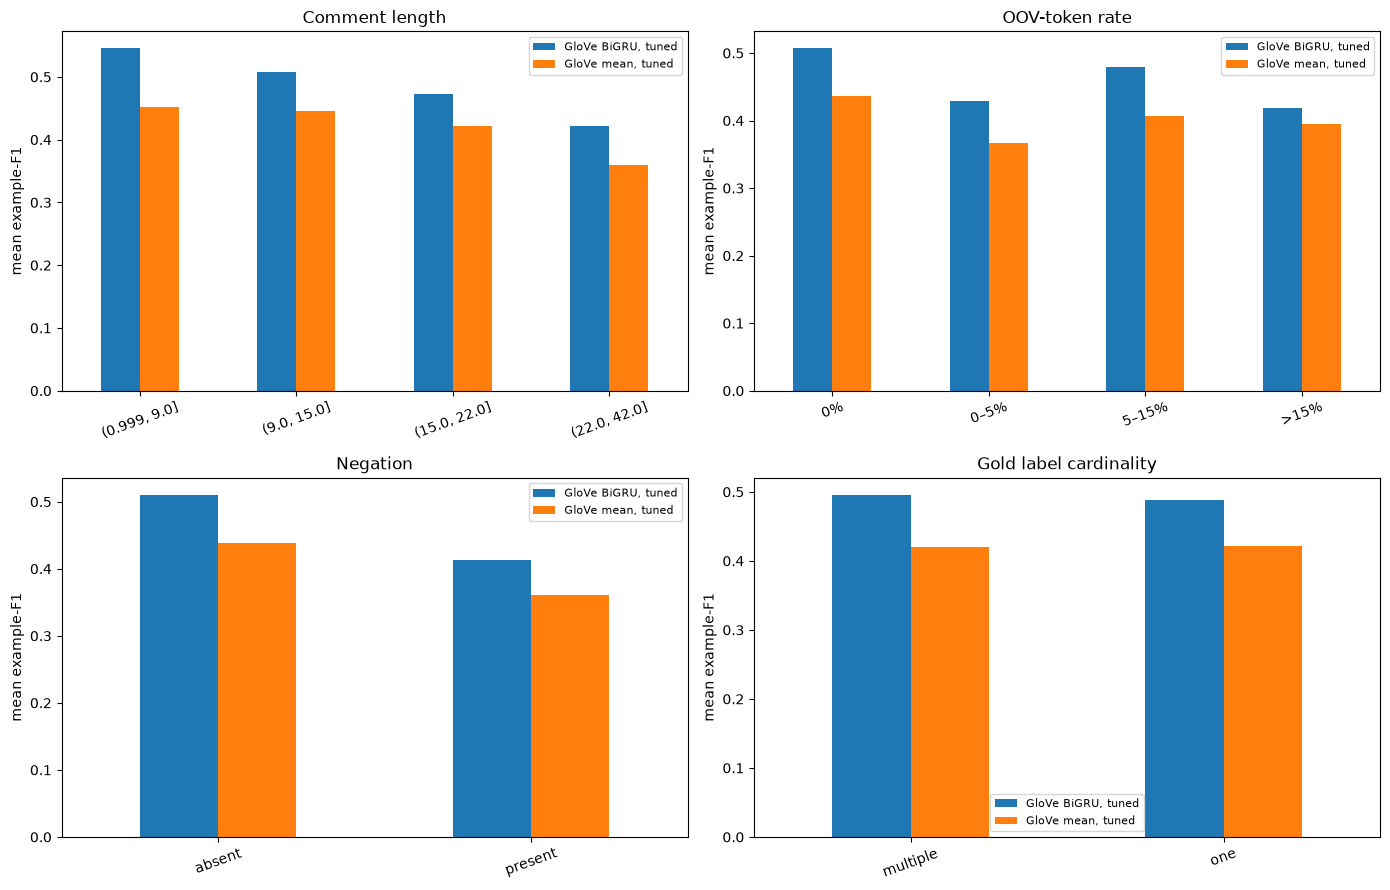

,feature,coefficient
4,label_count,-0.412
0,token_count,-0.253
2,negation,-0.165
1,oov_rate,-0.056
3,punctuation_rate,0.030


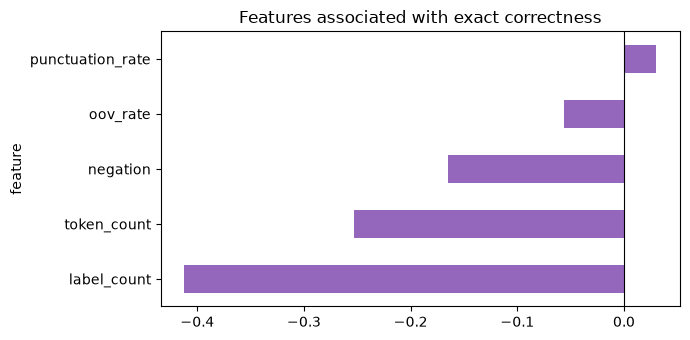

,text,gold,predicted,example_f1
0,"I figure if I'm being held up by my waist, I h...",neutral,approval,0.0
1,Never understood the attachment to cats person...,confusion,disapproval,0.0
2,"You seem worried, [NAME].",caring,sadness,0.0
3,You've got this. Hang in there. Please keep us...,gratitude,"remorse, sadness",0.0
4,Because [NAME] is a man child who can’t stand ...,disappointment,neutral,0.0
5,[NAME] is not our biggest need. [NAME] would b...,realization,"annoyance, disapproval",0.0
6,"Oh dear, The combination of drugs, alcohol and...",remorse,sadness,0.0
7,Your 'brother' had texted alot of girls and en...,amusement,curiosity,0.0
8,Still don’t know how [NAME] said him and [NAME...,curiosity,neutral,0.0
9,"Unfortunately, we do not routinely keep 20 lit...",neutral,<none>,0.0


In [7]:
dev_features = analysis_features(SPLITS["dev"].text, sequence_tokens["dev"], EMBEDDINGS, TARGETS["dev"])
analysis_frames = []
ensemble_predictions = {}
for name in finalists:
    probs = np.mean([run["probabilities"] for run in confirm_runs[name]], axis=0)
    threshold, _ = select_threshold(TARGETS["dev"], probs)
    predicted = (probs >= threshold).astype(int)
    ensemble_predictions[name] = predicted
    frame = dev_features.copy()
    frame["system"] = name
    frame["example_f1"] = example_f1(TARGETS["dev"], predicted)
    frame["exact"] = (TARGETS["dev"] == predicted).all(axis=1).astype(int)
    analysis_frames.append(frame)
analysis_data = pd.concat(analysis_frames, ignore_index=True)

analysis_data["length_bin"] = pd.qcut(analysis_data.token_count, 4, duplicates="drop")
analysis_data["oov_bin"] = pd.cut(analysis_data.oov_rate, [-.001, .001, .05, .15, 1],
                                  labels=["0%", "0–5%", "5–15%", ">15%"])
analysis_data["negation_label"] = analysis_data.negation.map({0:"absent", 1:"present"})
analysis_data["labels_bin"] = np.where(analysis_data.label_count.eq(1), "one", "multiple")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, column, title in zip(axes.flat, ["length_bin","oov_bin","negation_label","labels_bin"],
                             ["Comment length","OOV-token rate","Negation","Gold label cardinality"]):
    grouped = analysis_data.groupby([column,"system"], observed=True).example_f1.mean().unstack()
    grouped.plot.bar(ax=ax, rot=20); ax.set(title=title, xlabel="", ylabel="mean example-F1"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "error_analysis_groups.png", dpi=180, bbox_inches="tight"); plt.show()

selected_analysis = analysis_data[analysis_data.system.eq(SELECTED)].reset_index(drop=True)
feature_names = ["token_count", "oov_rate", "negation", "punctuation_rate", "label_count"]
error_model = make_pipeline(StandardScaler(), LogisticRegression(
    l1_ratio=1, solver="liblinear", class_weight="balanced", C=.5, random_state=0))
error_model.fit(selected_analysis[feature_names], selected_analysis.exact)
coefficients = pd.DataFrame({"feature": feature_names, "coefficient": error_model[-1].coef_[0]}).sort_values("coefficient")
display(coefficients.round(3))
coefficients.plot.barh(x="feature", y="coefficient", legend=False, color="tab:purple", figsize=(7,3.5),
                       title="Features associated with exact correctness")
plt.axvline(0, color="black", linewidth=.8); plt.tight_layout()
plt.savefig(PLOTS_DIR / "error_feature_coefficients.png", dpi=180, bbox_inches="tight"); plt.show()

def decode(row): return ", ".join(np.asarray(LABELS)[np.flatnonzero(row)]) or "<none>"
selected_pred = ensemble_predictions[SELECTED]
selected_scores = example_f1(TARGETS["dev"], selected_pred)
worst = np.argsort(selected_scores)[:10]
error_examples = pd.DataFrame({
    "text": SPLITS["dev"].text.iloc[worst].to_numpy(),
    "gold": [decode(TARGETS["dev"][i]) for i in worst],
    "predicted": [decode(selected_pred[i]) for i in worst],
    "example_f1": selected_scores[worst],
})
display(error_examples)


## Conclusions, limitations and sources

**How to read the notebook.** Coverage and cosine structure justify—but also delimit—the embedding choice. The screen identifies promising design choices; the matched-seed confirmation supports the architecture decision; the threshold curve fixes the multilabel operating point; test results answer whether Project 2 improves on Project 1; per-emotion and feature analyses reveal where aggregate scores conceal failures.

**Limitations.** GloVe assigns one context-independent vector per word, collapses all unknown words to one vector, and was trained on WikiGigaword rather than Reddit. The screen uses one subsample/seed and confirmation varies initialisation but not the official split. Weighted BCE and one global threshold may overpredict common or semantically broad labels; class-specific thresholds require careful nested validation. Rare emotions yield unstable per-class estimates. Error-regression coefficients are correlational. GoEmotions annotations are subjective and platform/domain biases limit generalisation.

**Sources.** Pennington, Socher & Manning (2014), *GloVe: Global Vectors for Word Representation*; the Gensim data mirror of Stanford's `glove-wiki-gigaword-50`; Demszky et al. (2020), *GoEmotions: A Dataset of Fine-Grained Emotions*; Assignment 2 `tutorial.ipynb` and supplied `part2` utilities; scikit-learn and PyTorch documentation.
